In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("Titanic-Dataset.csv.csv")

print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset shape: (891, 12)
Number of rows: 891
Number of columns: 12


In [4]:
display(df.head())
display(df.tail())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q



Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       

In [5]:
numerical_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

display(df[numerical_cols].describe())

Numerical columns: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
missing_count = df.isnull().sum()
missing_percent = (
    df.isnull().sum() / len(df) * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percent
})

display(missing_summary)

,Missing Count,Missing Percentage
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
Age,177,19.87
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00
Fare,0,0.00


In [7]:
cleaned_df = df.copy()

for col in numerical_cols:
    if cleaned_df[col].isnull().sum() > 0:
        cleaned_df[col] = cleaned_df[col].fillna(
            cleaned_df[col].median()
        )

for col in categorical_cols:
    if cleaned_df[col].isnull().sum() > 0:
        cleaned_df[col] = cleaned_df[col].fillna(
            cleaned_df[col].mode()[0]
        )

print("Missing values after imputation:")
display(cleaned_df.isnull().sum())

Missing values after imputation:


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [8]:
print("Duplicate rows:", cleaned_df.duplicated().sum())

cleaned_df = cleaned_df.drop_duplicates()

for col in categorical_cols:
    cleaned_df[col] = cleaned_df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

print("Duplicate rows after cleaning:",
      cleaned_df.duplicated().sum())

Duplicate rows: 0
Duplicate rows after cleaning: 0


In [9]:
display(cleaned_df[numerical_cols].describe())

if "Sex" in cleaned_df.columns:
    print("Sex frequency:")
    display(cleaned_df["Sex"].value_counts())

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Sex frequency:


,count
Sex,
male,577
female,314


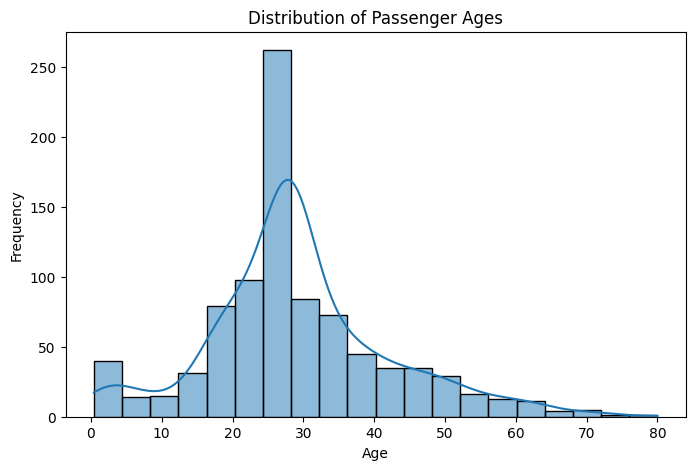

In [10]:
if "Age" in cleaned_df.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(cleaned_df["Age"], bins=20, kde=True)
    plt.title("Distribution of Passenger Ages")
    plt.xlabel("Age")
    plt.ylabel("Frequency")
    plt.show()

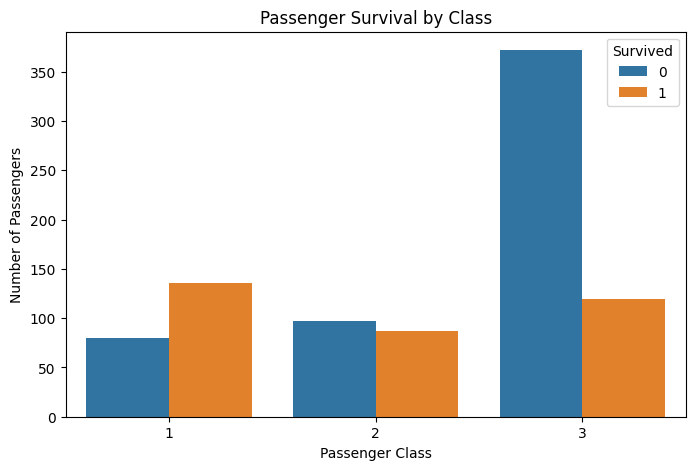

In [11]:
if {"Pclass", "Survived"}.issubset(cleaned_df.columns):
    plt.figure(figsize=(8, 5))
    sns.countplot(data=cleaned_df, x="Pclass", hue="Survived")
    plt.title("Passenger Survival by Class")
    plt.xlabel("Passenger Class")
    plt.ylabel("Number of Passengers")
    plt.show()

In [12]:
exclude_cols = ["Survived", "PassengerId"]

encoding_cols = [
    col for col in cleaned_df.select_dtypes(
        include=["object", "category"]
    ).columns
    if col not in exclude_cols
]

encoded_df = pd.get_dummies(
    cleaned_df,
    columns=encoding_cols,
    drop_first=False,
    dtype=int
)

print("Encoded dataset:")
display(encoded_df.head())

Encoded dataset:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,"Name_Abbing, Mr. Anthony","Name_Abbott, Mr. Rossmore Edward","Name_Abbott, Mrs. Stanton (Rosa Hunt)",...,Cabin_F G73,Cabin_F2,Cabin_F33,Cabin_F38,Cabin_F4,Cabin_G6,Cabin_T,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,22.0,1,0,7.2500,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,2,1,1,38.0,1,0,71.2833,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3,1,3,26.0,0,0,7.9250,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,4,1,1,35.0,1,0,53.1000,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,5,0,3,35.0,0,0,8.0500,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [13]:
from sklearn.preprocessing import StandardScaler

scale_cols = [
    col for col in ["Age", "Fare"]
    if col in encoded_df.columns
]

scaler = StandardScaler()

encoded_df[scale_cols] = scaler.fit_transform(
    encoded_df[scale_cols]
)

print("Scaled numerical columns:", scale_cols)

Scaled numerical columns: ['Age', 'Fare']


In [14]:
encoded_df.to_csv(
    "titanic_prepared.csv",
    index=False
)

print("Final dataset shape:", encoded_df.shape)
print("Remaining missing values:",
      encoded_df.isnull().sum().sum())
print("Remaining duplicates:",
      encoded_df.duplicated().sum())

display(encoded_df.head())

print("Prepared dataset saved as titanic_prepared.csv")

Final dataset shape: (891, 1731)
Remaining missing values: 0
Remaining duplicates: 0


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,"Name_Abbing, Mr. Anthony","Name_Abbott, Mr. Rossmore Edward","Name_Abbott, Mrs. Stanton (Rosa Hunt)",...,Cabin_F G73,Cabin_F2,Cabin_F33,Cabin_F38,Cabin_F4,Cabin_G6,Cabin_T,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,-0.565736,1,0,-0.502445,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,2,1,1,0.663861,1,0,0.786845,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3,1,3,-0.258337,0,0,-0.488854,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,4,1,1,0.433312,1,0,0.420730,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,5,0,3,0.433312,0,0,-0.486337,0,0,0,...,0,0,0,0,0,0,0,0,0,1


Prepared dataset saved as titanic_prepared.csv
